# A topographic ERT inverse with a known synthetic control

**Question:** Can the topographic M07 synthetic solver recover a finite conductor and predict held-out measurements?

**Level 3 — Solver experiment**  
**Prerequisites:** Wenner geometry, log resistivity, regularization and held-out validation; 60–90 min including the solve.



## Objectives

How much does a laterally bounded conductor change the potential field? Does a topographic 2D inverse predict measurements it did not fit? How much do its model and held-out scores move when the mesh or assumed errors change?



## Setup

Install exact notebook pins with `pip install numpy==2.2.6 matplotlib==3.10.8`, then the separate pinned engine: `./scripts/setup.ps1 -Notebooks` and `./scripts/setup.ps1 -Ert` (Windows), or `scripts/setup.sh --notebooks` and `scripts/setup.sh --ert`. pyGIMLi requires NumPy 2.5.3; it stays isolated from the main notebooks' NumPy 2.2.6.



Set `CAOS_TEMP_ROOT` in your shell to an absolute device-local temporary directory before invoking `scripts/run_notebooks.py`. The runner uses the configured value; it does not select or embed a machine-specific path. If the variable is missing, the method cell stops with a direct instruction.

## Data

The checked-in, SHA-256-verified receipt was generated by the deterministic experiment script. Set `RUN_SOLVER=True` in the experiment cell to rerun the numerical solve using the isolated `.venv-ert` runtime. The 28-electrode, four-spacing Wenner survey is generated by the script. The electrodes follow a curved surface; pyGIMLi computes responses for a 100 Ω m background containing a finite 25 Ω m body. A seeded 1% log-normal perturbation is applied. These are simulated observations with explicit truth, never the rights-restricted Slagdump field data.


## Method

The synthetic resistance measurements come from a 2D finite-element solution of the DC conductivity equation, with the actual electrode elevations and a finite conductive body. The inverse then uses pyGIMLi's ERT manager, numerical topographic geometric factors, a log-resistivity model and the repository's frozen settings. The primary split withholds every fifth datum within each AB-index span; the second fit withholds quadrupoles whose AB midpoint falls in the central 40–60% of the line.

The training objective is weighted data misfit plus smoothness regularization. Weights use the documented assumed 3% resistance error; this is deliberately not called instrument calibration. The experiment also reruns the fit with an alternate parameter mesh and doubled assumed errors. Those are sensitivity controls; they do not select a better model. Read the implementation and conditional stopping definition in `data-pipeline/ert.py`.
### M07 generated truth and split design

The fresh finite-element control has known truth and two withheld geometries; neither partition contains Slagdump observations.

In [1]:
from pathlib import Path
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Verify source ledger and local presence of raw ERT inputs.
import json
from pathlib import Path

ledger = json.loads((root / "data/source-ledger.json").read_text(encoding="utf-8"))
print("ledger mentions Slagdump:", "slagdump" in json.dumps(ledger).lower())
raw = list((root / "data").rglob("*.ohm"))
print("local .ohm files:", raw, "; inversion from field arrays possible:", bool(raw))


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
ledger mentions Slagdump: True
local .ohm files: [] ; inversion from field arrays possible: False


### Controlled QC and geometry experiment

Build an in-memory, explicitly synthetic Wenner `.ohm` survey with known elevations, nominal flat-halfspace response, seeded scatter and one injected outlier. Run the repository parser, flag-only QC, geometry factors and predeclared holdout. The factor calculation deliberately ignores elevation: compare its apparent-resistivity diagnostic with topographic relief and explain why this is **not** topographic correction or inversion. No field data or geology are inferred.

Inputs and outputs are synthetic; the flag preserves the measurement and the flat factor is only a diagnostic.

### Define a synthetic Wenner acquisition and strict source bytes

In [2]:
# Define the synthetic surface and Wenner ABMN rows.
import sys

sys.path.insert(0, str(root / "data-pipeline"))
import ert
import numpy as np
import matplotlib.pyplot as plt

ne = 16
x = np.arange(ne, dtype=float) * 2.0
z = 0.45 * np.sin(x / 7.0) + 0.012 * x
rows = []
for spacing in (1, 2, 3):
    for start in range(ne - 3 * spacing):
        rows.append(
            (
                start + 1,
                start + 1 + 3 * spacing,
                start + 1 + spacing,
                start + 1 + 2 * spacing,
            )
        )




### Serialize the synthetic survey format

The electrode surface and non-overlapping Wenner ABMN geometries are explicit arrays. This next step encodes them into the documented text format so the repository parser and inversion methods receive the same representation used by the pipeline.

In [3]:
# Serialize the synthetic survey format.
def source_bytes(resistance):
    header = [
        "# Synthetic teaching fixture; not field data",
        "# Wenner array; x/z in m; resistance in ohm",
        f"{ne}# Number of sensors",
        "#x z",
    ]
    sensors = [f"{xx:.6f} {zz:.6f}" for xx, zz in zip(x, z)]
    data_header = [f"{len(rows)}# Number of data", "#a b m n R"]
    measurements = [f"{a} {b} {m} {n} {value:.12g}" for (a, b, m, n), value in zip(rows, resistance)]
    return ("\n".join(header + sensors + data_header + measurements) + "\n").encode()


### Parse, flag and split the synthetic readings

In [4]:
# Parse noisy synthetic measurements and run product QC and holdout methods.
base = ert.parse_ohm_bytes(source_bytes(np.ones(len(rows))))
factors_base = ert.flat_halfspace_factors(base)
rng = np.random.default_rng(20261027)
resistance = 100.0 / factors_base * np.exp(rng.normal(0, 0.025, len(rows)))
outlier = min(5, len(resistance) - 1)
resistance[outlier] *= 12
s = ert.parse_ohm_bytes(source_bytes(resistance))
report = ert.qc(s)
train, held = ert.holdout_indices(s)
app = ert.flat_halfspace_factors(s) * s.resistance_ohm
print("electrodes and measurements", report["sensor_count"], report["measurement_count"])
print("relief and flagged rows", report["topographic_relief_m"], report["flagged_rows"])
print("injected row retained", outlier in range(len(resistance)))
print("training and held out", len(train), len(held))
print("apparent resistivity median Ω·m", float(np.median(app)))


electrodes and measurements 16 30
relief and flagged rows 0.639031 [5]
injected row retained True
training and held out 25 5
apparent resistivity median Ω·m 99.07252512562991


### Inspect geometry and apparent-resistivity diagnostics

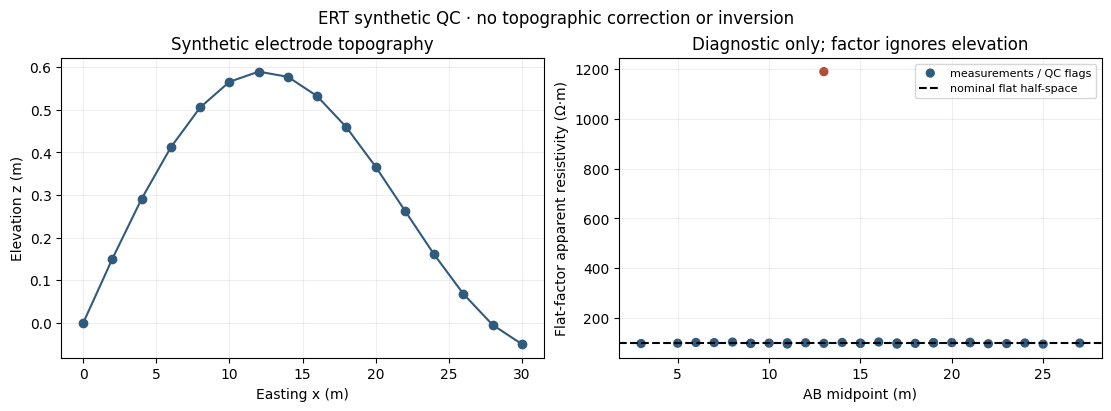

In [5]:
# Plot the synthetic electrode profile and flag-only apparent-resistivity readings.
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].plot(x, z, "o-", color="#315b7d")
ax[0].set(xlabel="Easting x (m)", ylabel="Elevation z (m)", title="Synthetic electrode topography")
ax[0].grid(alpha=0.2)
midpoint = (x[s.abmn[:, 0]] + x[s.abmn[:, 1]]) / 2
flagged = np.isin(np.arange(len(app)), report["flagged_rows"])
colors = np.where(flagged, "#b34a36", "#315b7d")
ax[1].scatter(midpoint, app, c=colors, s=32, label="measurements / QC flags")
ax[1].axhline(100, color="black", ls="--", label="nominal flat half-space")
ax[1].set(
    xlabel="AB midpoint (m)",
    ylabel="Flat-factor apparent resistivity (Ω·m)",
    title="Diagnostic only; factor ignores elevation",
)
ax[1].grid(alpha=0.2)
ax[1].legend(fontsize=8)
fig.suptitle("ERT synthetic QC · no topographic correction or inversion")
plt.show()


### Inspect the synthetic electrode line

The plotted surface and Wenner electrode positions define the topography and acquisition geometry used to generate the synthetic finite-element data. The view can expose indexing or elevation mistakes before inversion. It contains no Slagdump coordinates and no field resistances, so it cannot establish field coverage or support a field pseudosection.


### Apparent-resistivity transform

Apply the product geometric-factor method and inspect the readings by array span.

apparent resistivity Ω·m 94.84698797827475 99.07252512562991 1190.0751922800011


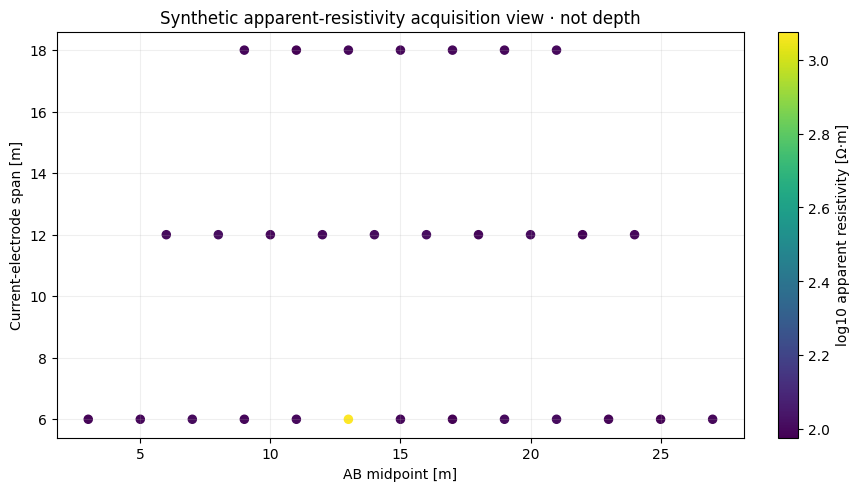

In [6]:
# Calculate apparent resistivity from parsed resistance and product geometric factors.
import matplotlib.pyplot as plt

factors = ert.flat_halfspace_factors(s)
rho_app = factors * s.resistance_ohm
ab = s.abmn
x = s.sensors_xz_m[:, 0]
midpoint = (x[ab[:, 0]] + x[ab[:, 1]]) / 2
span = x[ab[:, 1]] - x[ab[:, 0]]
fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
points = ax.scatter(midpoint, span, c=np.log10(rho_app), cmap="viridis", s=34)
fig.colorbar(points, ax=ax, label="log10 apparent resistivity [Ω·m]")
ax.set(
    xlabel="AB midpoint [m]",
    ylabel="Current-electrode span [m]",
    title="Synthetic apparent-resistivity acquisition view · not depth",
)
ax.grid(alpha=0.2)
print("apparent resistivity Ω·m", float(rho_app.min()), float(np.median(rho_app)), float(rho_app.max()))
plt.show()


The geometric factor converts each synthetic resistance to apparent resistivity under a flat, homogeneous half-space approximation. The span–midpoint view shows how array scale and position vary along this topographic line; it is not a depth image. Because the true body is finite and the surface is irregular, apparent resistivity here must not be read as a local cell value or as Slagdump evidence.


The figure reports calculated ert quantities in the units on the axes. It supports comparison under the stated assumptions, but does not establish field truth, geological uniqueness or source rights. Read the printed numerical diagnostics with the plotted pattern; visual similarity alone is not validation.
### Experiment — run the forward and inverse solvers

In [7]:
import os
# Run the isolated M07 pipeline now; the output is generated during this execution.
import hashlib, json, os, subprocess
from pathlib import Path

try:
    temp_root_value = os.environ["CAOS_TEMP_ROOT"]
except KeyError as error:
    raise RuntimeError(
        "Set CAOS_TEMP_ROOT to the device-configured temporary root, then rerun scripts/run_notebooks.py."
    ) from error
temp_root = Path(temp_root_value).expanduser()
if not temp_root.is_absolute():
    raise RuntimeError("CAOS_TEMP_ROOT must be an absolute device-local path.")
work = temp_root / "caos-geophysics-ert-notebook"
work.mkdir(parents=True, exist_ok=True)
output = work / "m07-current-run.json"
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-ert" / "Scripts" / "python.exe"
if not engine.is_file():
    engine = engine_root / ".venv-ert" / "bin" / "python"
if not engine.is_file():
    raise RuntimeError("Build the isolated pyGIMLi environment with scripts/setup.ps1 -Ert")
command = [str(engine), str(root / "data-pipeline" / "ert_synthetic_experiment.py"), "--output", str(output)]


### Execute the pinned pyGIMLi experiment

The command uses the isolated solver environment and writes a fresh receipt beneath the caller-configured root. The returned JSON is checked for the expected synthetic source identity and summarized with its hash and independent validation scores.

In [8]:
# Execute the pinned pyGIMLi experiment.
completed = subprocess.run(command, cwd=root, capture_output=True, text=True, timeout=600)
if completed.returncode:
    raise RuntimeError(completed.stdout + "\n" + completed.stderr[-4000:])
payload = output.read_bytes()
experiment = json.loads(payload)
assert experiment["source_id"] == "original-synthetic-ert-control"
assert experiment["experiment"]["is_field_data"] is False
print("synthetic input SHA-256:", experiment["source_sha256"])
print("status:", experiment["inverse_status"], "measurements:", experiment["qc"]["measurement_count"])
print("interleaved heldout log-RMSE =", round(experiment["inverse"]["heldout_log_r_rmse"], 3))
print("spatial-blocked heldout log-RMSE =", round(experiment["blocked_validation"]["heldout_log_r_rmse"], 3))


synthetic input SHA-256: 7d0851c20feea718493b62dd9c1c5b71fdbf364fbe46982d881e7fc93ae62316
status: passed measurements: 82
interleaved heldout log-RMSE = 0.031
spatial-blocked heldout log-RMSE = 0.066


### Compare truth, recovered model, coverage and residuals

In [9]:
# Prepare solver arrays, mesh coordinates and the exact validation partition.
import numpy as np
from matplotlib.tri import Triangulation
inv = experiment.get("inverse")
if inv is None:
    raise RuntimeError("inverse did not produce a model: " + experiment.get("inverse_reason", "unknown reason"))
coords = np.asarray(inv["model_cell_center_xz_m"])
depth = -coords[:, 1]
tri = Triangulation(coords[:, 0], depth)
truth = np.asarray(experiment["synthetic_truth_comparison"]["truth_resistivity_ohm_m_at_parameter_cell_centers"])
model = np.asarray(inv["model_resistivity_ohm_m"])
coverage = np.round(np.asarray(inv["coverage_log10_sensitivity_per_cell"]), 2)
model_log10_display = np.round(np.log10(model) * 10) / 10
observed = np.asarray(inv["observed_r_ohm"])
predicted = np.asarray(inv["predicted_r_ohm"])
train = np.asarray(experiment["split"]["training_rows"], dtype=int)
held = np.asarray(experiment["split"]["heldout_rows"], dtype=int)
xel = np.asarray(experiment["experiment"]["geometry"]["electrode_x_m"])
spans = []
for spacing in (1, 2, 3, 4):
    for start in range(len(xel) - 3 * spacing):
        spans.append((start, start + 3 * spacing))
midpoints = np.asarray([(xel[a] + xel[b]) / 2 for a, b in spans])


Compare known truth with the inverse model and plot Jacobian coverage separately. Coverage measures sensitivity concentration, not resolution; the synthetic truth panel is available only because this is a controlled test.

[Text(0.5, 1.0, 'Sensitivity coverage (not resolution)'),
 Text(0.5, 0, 'Distance (m)'),
 Text(0, 0.5, 'Depth (m)'),
 (36.0, 0.0)]

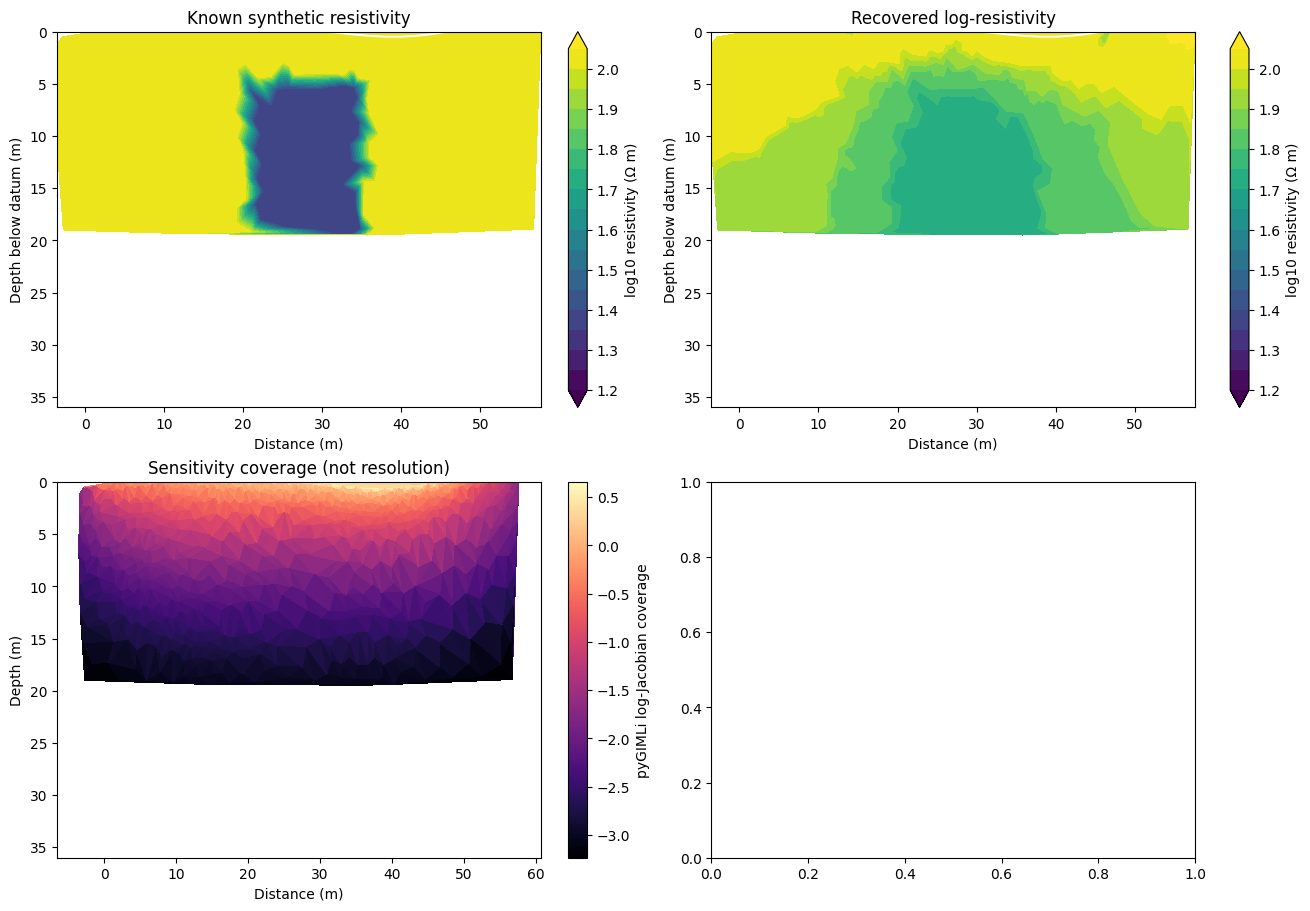

In [10]:
# Plot known synthetic truth, the recovered model and sensitivity coverage.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for axis, values, title in (
    (ax[0, 0], truth, "Known synthetic resistivity"),
    (ax[0, 1], model, "Recovered log-resistivity"),
):
    image = axis.tricontourf(
        tri,
        np.log10(values) if values is truth else model_log10_display,
        levels=np.linspace(1.2, 2.05, 18),
        cmap="viridis",
        extend="both",
    )
    fig.colorbar(image, ax=axis, label="log10 resistivity (Ω m)")
    electrode_x = experiment["experiment"]["geometry"]["electrode_x_m"]
    electrode_z = experiment["experiment"]["geometry"]["electrode_z_m"]
    axis.plot(electrode_x, -np.asarray(electrode_z), color="white", lw=1.4)
    axis.set(title=title, xlabel="Distance (m)", ylabel="Depth below datum (m)", ylim=(36, 0))
image = ax[1, 0].tripcolor(tri, coverage, shading="flat", cmap="magma")
fig.colorbar(image, ax=ax[1, 0], label="pyGIMLi log-Jacobian coverage")
ax[1, 0].set(
    title="Sensitivity coverage (not resolution)",
    xlabel="Distance (m)",
    ylabel="Depth (m)",
    ylim=(36, 0),
)


The scatter plot separates fitted from withheld rows and shows signed log-resistance residuals against acquisition midpoint. Spatial structure in the withheld points would indicate prediction error not visible from a single aggregate RMSE. These are residuals from one seeded synthetic mesh and noise model; they assess that split only, not field accuracy or geological uniqueness.


In [11]:
# Plot signed residuals by acquisition midpoint and report independent scores.
ax[1, 1].scatter(
    midpoints[train],
    np.round(np.log(predicted[train] / observed[train]), 3),
    s=18,
    label="training",
    alpha=0.75,
)
ax[1, 1].scatter(
    midpoints[held],
    np.round(np.log(predicted[held] / observed[held]), 3),
    s=30,
    label="held out",
    alpha=0.9,
)
ax[1, 1].axhline(0, color="black", lw=0.8)
ax[1, 1].set(
    title="Signed log-resistance residual",
    xlabel="AB midpoint (m)",
    ylabel="ln(predicted / observed)",
)
ax[1, 1].legend()
fig.suptitle("Topographic 2D ERT · synthetic control · not field geology", fontsize=14)
plt.show()


### Read the synthetic inverse metrics

The residual panel above is indexed by acquisition midpoint, with training and held-out rows distinguished. These metrics report inverse status, model size, truth error, held-out improvements, and sensitivity checks for the same freshly computed experiment.

The plotted model panel bins log10 resistivity to 0.1 for stable visual categories; the full-precision model and coverage arrays remain in the receipt. Printed error scores use three decimals because repeated pyGIMLi solves vary below that reporting precision.

Pixel drift is bounded by a declared PNG tolerance: at most 0.05% changed pixels and normalized mean absolute error 0.0002. The baked figure and fresh figure were pixel-compared; the full numerical receipt remains the scientific record.

In [12]:
# Read the synthetic inverse metrics.
print("inverse status", experiment["inverse_status"])
print("parameter cells", inv["mesh_cells"])
print(
    "cellwise log10 truth RMSE =",
    round(experiment["synthetic_truth_comparison"]["log10_rmse_over_parameter_cells"], 3),
)
print("interleaved held-out improvement", round(inv["heldout_improvement_vs_homogeneous"], 3))
print("blocked held-out improvement", round(experiment["blocked_validation"]["improvement_vs_homogeneous"], 3))
print(
    "alternate-mesh held-out log RMSE =",
    round(experiment["sensitivity"]["alternate_mesh"]["heldout_log_r_rmse"], 3),
)
print(
    "doubled-error held-out log RMSE =",
    round(experiment["sensitivity"]["doubled_assumed_error"]["heldout_log_r_rmse"], 3),
)


inverse status passed
parameter cells 835
cellwise log10 truth RMSE = 0.121
interleaved held-out improvement 0.657
blocked held-out improvement 0.558
alternate-mesh held-out log RMSE = 0.031
doubled-error held-out log RMSE = 0.029


Re-run product QC before interpreting the physical inverse.

In [13]:
# Re-run product QC before interpreting the physical inverse.
qc_repeat = ert.qc(s)
print("flags:", qc_repeat["flagged_rows"], "relief m:", qc_repeat["topographic_relief_m"])


flags: [5] relief m: 0.639031


Recompute flat analytical factors for the same synthetic readings.

In [14]:
# Recompute flat analytical factors for the same synthetic readings.
flat_factors = ert.flat_halfspace_factors(s)
print("factor range m:", float(flat_factors.min()), float(flat_factors.max()))


factor range m: 12.566370614359172 37.69911184307752


Recompute the frozen within-spacing holdout.

In [15]:
# Recompute the frozen within-spacing holdout.
train_rows, held_rows = ert.holdout_indices(s)
print("training:", len(train_rows), "held out:", len(held_rows))


training: 25 held out: 5


## Results

The interleaved and spatial-blocked tests answer different questions: the first interpolates between omitted quadrupoles, while the second challenges transfer across the line. The blocked log-RMSE is higher, and the Jacobian coverage map is sensitivity rather than spatial resolution. Mesh and error perturbations remain close on this one generated finite-element case; none of these results transfers to absent Slagdump field data.

**Answer:** The fresh M07 run passed with 82 measurements and 835 parameter cells. Held-out log-resistance RMSE is 0.03129 for the interleaved split and 0.06564 for spatial blocking; cellwise log10 truth RMSE is 0.1208. The alternate-mesh and doubled-error scores are 0.0315 and 0.0288.


## Summary

The synthetic gates pass, but spatial blocking roughly doubles the held-out error relative to interleaving. This is a synthetic finite-element truth test; it does not qualify the separate Slagdump case whose raw `.ohm` source remains absent.



## References

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)